# 1. Testare pe datasetul din 2018 -cel original la mine

In [ ]:
#@title
import tensorflow as tf
from tensorflow import keras
import requests
from google.colab import files
from PIL import Image
import numpy as np
from IPython.core.display import display, HTML

In [ ]:
import requests
# Download model and weights
model = requests.get('https://github.com/ACM-Research/image-classification-cnn/raw/master/OCT-cnn/python_model/variables/model.h5', allow_redirects=True)
open('model.h5', 'wb').write(model.content)

19955088

In [ ]:
# Load model
model = tf.keras.models.load_model('model.h5',compile=False)
labels = ['CNV', 'DME', 'DRUSEN', 'NORMAL']

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,638,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,658,436 (6.33 MB)

 Trainable params: 1,658,436 (6.33 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/kermany2018")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'kermany2018' dataset.
Path to dataset files: /kaggle/input/kermany2018


In [ ]:
import os
import numpy as np
from PIL import Image
from IPython.display import display, HTML
import pandas as pd

base_dir = '/kaggle/input/kermany2018/oct2017/OCT2017 /test'
labels = ['CNV', 'DME', 'DRUSEN', 'NORMAL']

results = []
max_images = 80000
count = 0

for label in labels:
    folder = os.path.join(base_dir, label)
    files = [f for f in os.listdir(folder) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

    for fname in files:

        img_path = os.path.join(folder, fname)
        img = Image.open(img_path).resize((180,180))
        img_arr = np.asarray(img)

        if img_arr.ndim == 2:
            img_arr = np.stack((img_arr,)*3, axis=-1)

        batch = img_arr[np.newaxis, ...]
        prediction = np.argmax(model.predict(batch, verbose=0), axis=-1)
        predicted_label = labels[prediction[0]]

        # Afișează progresul
        if count % 500 == 0:
            print(f"Procesate: {count} imagini...")

        results.append({
            "Imagine": fname,
            "Clasa reală": label,
            "Predicție": predicted_label
        })

        count += 1

    if count >= max_images:
        break

print(f"Procesarea s-a oprit după {count} imagini.")

# Salvare rezultate
df = pd.DataFrame(results)
df.to_csv('OCT_results_train_5000.csv', index=False)
print("Rezultatele au fost salvate ca 'OCT_results_train_5000.csv'")


Procesate: 0 imagini...
Procesate: 500 imagini...
Procesarea s-a oprit după 968 imagini.
Rezultatele au fost salvate ca 'OCT_results_train_5000.csv'


/tmp/ipython-input-2463473721.py:23: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  class_accuracy = df_filtered.groupby("Clasa reală").apply(


,precision,recall,f1-score,support
CNV,0.967213,0.975207,0.971193,242.0
DRUSEN,1.000000,0.958678,0.978903,242.0
NORMAL,0.991770,0.995868,0.993814,242.0
micro avg,0.986092,0.976584,0.981315,726.0
macro avg,0.986328,0.976584,0.981304,726.0
weighted avg,0.986328,0.976584,0.981304,726.0


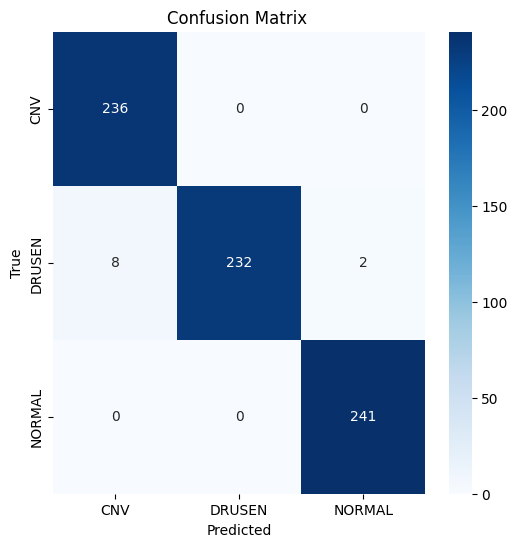

In [ ]:
import pandas as pd
from IPython.display import display, HTML
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Încarc CSV-ul
df = pd.read_csv('/content/OCT_results_train_5000.csv')

# Filtrez clasele
keep_classes = ["CNV", "DRUSEN", "NORMAL"]
df_filtered = df[df["Clasa reală"].isin(keep_classes)]

# Acuratețe globală
total = len(df_filtered)
correct = (df_filtered["Clasa reală"] == df_filtered["Predicție"]).sum()
accuracy_total = correct / total * 100

display(HTML(f"<h2 style='color:navy;'>Overall Accuracy: {accuracy_total:.2f}% ({correct}/{total})</h2>"))

# Acuratețe per clasă
class_accuracy = df_filtered.groupby("Clasa reală").apply(
    lambda x: 100 * (x["Clasa reală"] == x["Predicție"]).sum() / len(x)
).reset_index(name="Accuracy (%)")

acc_text = "<h3 style='color:darkgreen;'>Accuracy per class :</h3><ul>"
for _, row in class_accuracy.iterrows():
    acc_text += f"<li><b>{row['Clasa reală']}</b>: {row['Accuracy (%)']:.2f}%</li>"
acc_text += "</ul>"
display(HTML(acc_text))

# Raport
y_true = df_filtered["Clasa reală"]
y_pred = df_filtered["Predicție"]
report = classification_report(y_true, y_pred, labels=keep_classes, output_dict=True)
report_df = pd.DataFrame(report).transpose()

display(HTML("<h3 style='color:darkred;'>Classification Report :</h3>"))
display(report_df)

# Matrice confuzie
cm = confusion_matrix(y_true, y_pred, labels=keep_classes)
plt.figure(figsize=(6,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=keep_classes,
            yticklabels=keep_classes)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix ")
plt.show()


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import tensorflow as tf


# Parametri
BATCH_SIZE = 32
class_names = ["CNV", "DME", "DRUSEN", "NORMAL"]

# Functia de preprocesare
import cv2

TARGET_SIZE = (180, 180)
def preprocess_oct(image):
    if len(image.shape) == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    image = cv2.resize(image, TARGET_SIZE)
    if image.dtype != np.uint8:
        image = (image * 255).astype(np.uint8) if image.max() <= 1.0 else image.astype(np.uint8)
    image = cv2.medianBlur(image, 3)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    image = clahe.apply(image)
    image = image.astype("float32") / 255.0
    return np.stack([image, image, image], axis=-1)


# Creeaza lista cu imagini si etichete
ROOT = "/content/drive/MyDrive/NEH_UT_2021RetinalOCTDataset"
class_names = ["CNV", "DME", "DRUSEN", "NORMAL"]
VALID_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')

paths = []
labels = []

for idx, cls in enumerate(class_names):
    folder = os.path.join(ROOT, cls)
    print(f"Scanning folder: {folder}")

    for root_dir, _, files in os.walk(folder):
        for fname in files:
            if fname.lower().endswith(VALID_EXT):
                paths.append(os.path.join(root_dir, fname))
                labels.append(idx)

labels = np.array(labels)
print(f"Total images found: {len(paths)}")

# Batch-by-batch predict
keras_preds = []

for i in tqdm(range(0, len(paths), BATCH_SIZE), desc="Predicting batches"):
    batch_paths = paths[i:i+BATCH_SIZE]
    X_batch = []
    for p in batch_paths:
        img = tf.keras.utils.load_img(p, target_size=TARGET_SIZE)
        img = tf.keras.utils.img_to_array(img)
        img = preprocess_oct(img)
        X_batch.append(img)
    X_batch = np.array(X_batch)
    preds = np.argmax(model.predict(X_batch, verbose=0), axis=1)
    keras_preds.extend(preds)

keras_preds = np.array(keras_preds)



Scanning folder: /content/drive/MyDrive/NEH_UT_2021RetinalOCTDataset/CNV
Scanning folder: /content/drive/MyDrive/NEH_UT_2021RetinalOCTDataset/DME
Scanning folder: /content/drive/MyDrive/NEH_UT_2021RetinalOCTDataset/DRUSEN
Scanning folder: /content/drive/MyDrive/NEH_UT_2021RetinalOCTDataset/NORMAL
Total images found: 3571


Predicting batches: 100%|██████████| 112/112 [25:25<00:00, 13.62s/it]


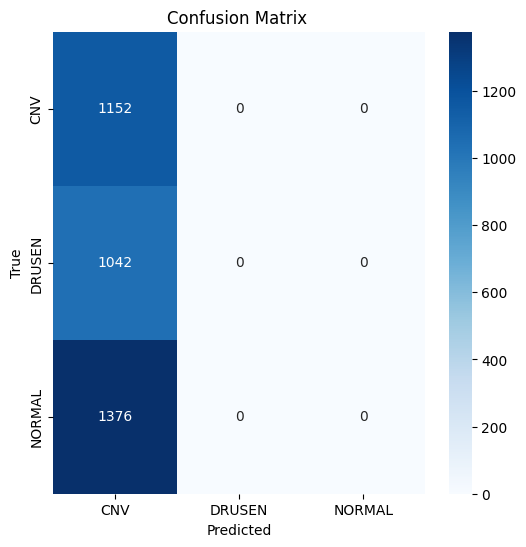


=== Acuratețe per clasă  ===
CNV: 1.0000
DRUSEN: 0.0000
NORMAL: 0.0000

Classification Report :

              precision    recall  f1-score   support

         CNV       0.32      1.00      0.49      1152
      DRUSEN       0.00      0.00      0.00      1042
      NORMAL       0.00      0.00      0.00      1376

    accuracy                           0.32      3570
   macro avg       0.11      0.33      0.16      3570
weighted avg       0.10      0.32      0.16      3570

Test Accuracy : 32.27%


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Indici clase
keep_idx = [0, 2, 3]
class_names_filtered = ["CNV", "DRUSEN", "NORMAL"]

# Matrice confuzie pe toate clasele
cm_full = confusion_matrix(labels, keras_preds, labels=[0,1,2,3])

# Matrice confuzie filtrată
cm_filtered = cm_full[np.ix_(keep_idx, keep_idx)]

plt.figure(figsize=(6,6))
sns.heatmap(cm_filtered, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names_filtered, yticklabels=class_names_filtered)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix ")
plt.show()

# Acuratețe per clasă
class_acc_filtered = cm_filtered.diagonal() / cm_filtered.sum(axis=1)
print("\n=== Acuratețe per clasă  ===")
for cls, acc in zip(class_names_filtered, class_acc_filtered):
    print(f"{cls}: {acc:.4f}")

# Raport
y_true_filtered = labels[np.isin(labels, keep_idx)]
y_pred_filtered = keras_preds[np.isin(labels, keep_idx)]

report_filtered = classification_report(
    y_true_filtered,
    y_pred_filtered,
    labels=keep_idx,
    target_names=class_names_filtered
)

print("\nClassification Report :\n")
print(report_filtered)

# Acuratețe globală
acc_total_filtered = accuracy_score(y_true_filtered, y_pred_filtered)
print(f"Test Accuracy : {acc_total_filtered*100:.2f}%")
